# Griffiths et al. 2021 — Breast Cancer · 04 EMT-TF Expression
Unconditional final step (outside the gate chain). Score a **widened** EMT-TF panel (Snail/Zeb/Twist **plus** the FOXC and PRRX mesenchymal families; **VIM excluded** — vimentin is a mesenchymal marker, not a transcription factor), **gate on detectable expression**, and overlay the two most-informative detected factors as a **categorical thresholded-expresser overlay on a grey manifold** (the reference style — not a continuous single-gene colormap).

In [1]:
%matplotlib inline
import os, sys
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc
from scipy.stats import spearmanr
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                     # Griffiths2021_Breast-3
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # Breast
dataset = 'Data_Griffiths2021_Breast'                    # on-disk input (no -N suffix)
pth  = os.path.join(*([os.pardir]*6))                    # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', dataset)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb   = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))  # carries oriented X_umap + pseudotime
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime %.2f -> %.2f' % (t.min(), t.max()))

cells: 108658 | pseudotime 0.00 -> 12.09


### Panel scan — detection-gated, sorted by pseudotime correlation

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
family = {'SNAI1':'Snail','SNAI2':'Snail','ZEB1':'Zeb','ZEB2':'Zeb','TWIST1':'Twist',
          'TWIST2':'Twist','FOXC1':'FOXC','FOXC2':'FOXC','PRRX1':'PRRX','PRRX2':'PRRX'}
present = [g for g in panel if g in adata.var_names]
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = [(g, float((X[:,j]>0).mean()), spearmanr(tn, X[:,j])[0]) for j, g in enumerate(present)]
df = pd.DataFrame(rows, columns=['gene','detect_frac','rho_pt']).sort_values('rho_pt')
print(df.to_string(index=False))
det = df[df.detect_frac >= 0.02].sort_values('detect_frac', ascending=False)
print('\ndetection-gated (>=2% expressing):'); print(det.to_string(index=False))
# most-detectable factor, then the most-detectable factor from a DIFFERENT family (reference intent:
# two distinct mesenchymal families rather than two paralogues of one)
top = det.iloc[0].gene
alt = det[det.gene.map(family) != family[top]]
second = alt.iloc[0].gene if len(alt) else det.iloc[1].gene
picks = df[df.gene.isin([top, second])].sort_values('rho_pt')
early_tf, late_tf = picks.iloc[0].gene, picks.iloc[-1].gene
print(f'\noverlay (two families): {early_tf} + {late_tf}')

  gene  detect_frac    rho_pt
 PRRX1     0.044930 -0.019310
  ZEB1     0.089299 -0.015117
  ZEB2     0.051225 -0.015047
 PRRX2     0.016041 -0.014534
TWIST2     0.008126 -0.008257
 FOXC1     0.005724 -0.004896
 FOXC2     0.000322 -0.004068
 SNAI2     0.003470 -0.002302
 SNAI1     0.002209 -0.002260
TWIST1     0.016888 -0.001572

detection-gated (>=2% expressing):
 gene  detect_frac    rho_pt
 ZEB1     0.089299 -0.015117
 ZEB2     0.051225 -0.015047
PRRX1     0.044930 -0.019310

overlay (two families): PRRX1 + ZEB1


### Figure — categorical thresholded-expresser overlay on the grey manifold

detected EMT-TF fractions: {'PRRX1': 0.045, 'ZEB1': 0.089}


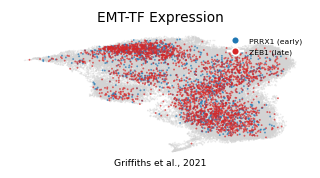

In [5]:
def vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
g_plt = {early_tf: 'tab:blue', late_tf: 'tab:red'}
thr = {g: (np.quantile(vec(g)[vec(g)>0], 0.75) if (vec(g)>0).any() else 0.0) for g in g_plt}
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, size=4, alpha=.4, frameon=False, show=False, ax=ax)
for g, col in g_plt.items():
    sel = adata[vec(g) > thr[g]].copy()
    sc.pl.umap(sel, na_color=col, size=6, alpha=.7, frameon=False, show=False, ax=ax)
ax.set_title('EMT-TF Expression', size=9)
ax.text(.5, -.06, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
handles = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=5,
                  label=f'{g} ({"early" if g==early_tf else "late"})') for g, c in g_plt.items()]
ax.legend(handles=handles, loc='upper right', fontsize=5, frameon=False)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
print('detected EMT-TF fractions:', {g: round(float((vec(g)>0).mean()),3) for g in g_plt})

EMT transcription factors are only sparsely expressed in this ER+ luminal population (ZEB1 highest at ≈9%, all others <6%) and none track pseudotime (|ρ|<0.02) — consistent with the weak embryonic-module signal. The two most-detectable factors across families (ZEB1, PRRX1) are overlaid; the canonical Snail/Twist factors are near-absent here.